In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from matplotlib.collections import PolyCollection
# %matplotlib notebook
%matplotlib widget

from os import makedirs
from os.path import join

import os

from scipy.ndimage import gaussian_filter
from scipy.linalg import sqrtm

import sys
sys.path.append('/home/abenneck/equivariance_model') # potentially add path to the moment kernels library if it is not in this path
import moment_kernels as mk



import nibabel as nib

import matplotlib.pyplot as plt

### Helper functions from gt_ap.ipynb

In [2]:
def bb_slice_filter(all_bb, ax_idx, slice_val):
    """
    NOTE: Each elem of all_bb should have at minimum these first 6 values [ax0_min, ax0_max, ax1_min, ax1_max, ax2_min, ax2_max, ...]
    """
    bb_out = []
    for bb in all_bb:
        if ax_idx == 0 and bb[0] <= slice_val and bb[1] >= slice_val:
            bb_out.append(bb)
        elif ax_idx == 1 and bb[2] <= slice_val and bb[3] >= slice_val:
            bb_out.append(bb)
        elif ax_idx == 2 and bb[4] <= slice_val and bb[5] >= slice_val:
            bb_out.append(bb)
        else:
            continue

    if bb_out == []:
        return np.array([])
    return np.stack(bb_out, axis=0)

def gt_mask_to_bb_list(mask_path, verbose=False):
    """
    Converts an integer-valued array into a set of bounding boxes around each unique instance.
    """
    # Load the GT annotation
    mask = nib.load(mask_path)
    
    # 0: Bg, 1: Annotated bg, 2+: Cell ID
    gt_bb = []
    vals_to_skip = [0, 1]
    n_cells = len(np.unique(mask.get_fdata())) - 2 # 0 is bg and 1 is annotated bg
    for val in np.unique(mask.get_fdata()):
        if val in vals_to_skip:
            continue
        mask_cell = np.copy(mask.get_fdata())
        mask_cell[mask_cell != val] = 0.0
        mask_cell[mask_cell == val] = 1.0
        if verbose:
            print(f'Cell {(val-1).astype(int)} / {n_cells} volume of {np.sum(mask_cell).astype(int)} voxels')
        all_x, all_y, all_z = np.where(mask_cell == 1.0)
        gt_bb.append([min(all_x).item(), max(all_x).item(), min(all_y).item(), max(all_y).item(), min(all_z).item(), max(all_z).item(), int(val)])

    return gt_bb

def yolo_output_to_bb_list(out):
    return out.reshape(out.shape[0]*out.shape[1]*out.shape[2],out.shape[3])

def stardist_to_bb_list(raw_output, mode='2D'):
    """
    Converts a standard output from the 2D or 3D StarDist models to a set of bounding boxes
    """

    bb_out = []
    if mode == '2D':
        for i in range(len(raw_output['coord'])):
            coords = raw_output['coord'][i]
            center = raw_output['points'][i]
            prob = float(raw_output['prob'][i])
    
            xmin = float(min(coords[1]))
            xmax = float(max(coords[1]))
            ymin = float(min(coords[0]))
            ymax = float(max(coords[0]))
    
            bb_out.append([xmin, xmax, ymin, ymax, prob])
    elif mode == '3D':
        n_ray = raw_output['dist'].shape[1]
        n_cells = raw_output['dist'].shape[0]
        n_dim = raw_output['points'].shape[1]
        for i in range(n_cells):
            prob = raw_output['prob'][i]
            center = raw_output['points'][i]
            n_vectors = [raw_output['rays_vertices'][j]*raw_output['dist'][i][j] for j in range(n_ray)]
            n_vectors = np.asarray(n_vectors) + center
        
            xmin, ymin, zmin = np.min(n_vectors, axis=0)
            xmax, ymax, zmax = np.max(n_vectors, axis=0)
        
            bb_out.append([xmin, xmax, ymin, ymax, zmin, zmax, prob])
    else:
        print(f'Invalid mode - {mode}; Expected 2D or 3D')
        
    return np.asarray(bb_out)

def cellpose_to_bb_list(mask, verbose=False):
    """
    Converts an integer-valued array into a set of bounding boxes around each unique instance.

    Output bbox format: [xmin xmax ymin ymax zmin zmax cell# conf]
    """
    # 0: Bg, 1+: Cell ID
    bb_out = []
    vals_to_skip = [0]
    n_cells = len(np.unique(mask)) - 1 # 0 is bg
    for val in np.unique(mask):
        if val in vals_to_skip:
            continue
        mask_cell = np.copy(mask)
        mask_cell[mask_cell != val] = 0.0
        mask_cell[mask_cell == val] = 1.0
        if verbose:
            print(f'Cell {(val-1).astype(int)} / {n_cells} volume of {np.sum(mask_cell).astype(int)} voxels')
        all_x, all_y, all_z = np.where(mask_cell == 1.0)
        bb_out.append([min(all_x).item(), max(all_x).item(), min(all_y).item(), max(all_y).item(), min(all_z).item(), max(all_z).item(), int(val), 1.0])
    return np.array(bb_out)

def preprocess_3D(img, upsample = True, gamma = True, norm = True):

    img_out = np.copy(img)
    
    # Apply a gamma correction (gamma = 1/2)
    if gamma:
        img_out = img_out**(1/2)

    # Normalize the image to [0,1]
    if normalize:
        # img_min = np.min(img,axis=(-1,-2,-3),keepdims=True)
        # img_max = np.max(img,axis=(-1,-2,-3),keepdims=True)
        # img_out = (img_out - img_min) / (img_max - img_min)
        img_out = normalize(img_out)
        
    # Upsample the image by a factor of 2 (Inc the size of each voxel from 1 to 2x2x2)
    if upsample:
        out_shape = [i*2 for i in img.shape]
        img_up = np.zeros(out_shape)
    
        img_up[::2,::2,::2]   = img_out
        img_up[::2,1::2,::2]  = img_out
        img_up[1::2,::2,::2]  = img_out
        img_up[1::2,1::2,::2] = img_out
        
        img_up[::2,::2,1::2]   = img_out
        img_up[::2,1::2,1::2]  = img_out
        img_up[1::2,::2,1::2]  = img_out
        img_up[1::2,1::2,1::2] = img_out

        img_out = img_up

    return img_out

# Convert all bb coords in 'bb_list' to the appropriate coordinate space (relative to the annotated region, with origin in the upper left corner)
def convert_bb_units(bb_list):
    bb_out = []
    for bb in bb_list:
        new_bb = [2*(val-96) for val in bb[:6]]
        new_bb.extend(bb[6:])
        bb_out.append(new_bb)
    return np.array(bb_out)

def remove_low_conf_bb(data, conf_idx = -4):
    """
    Remove all bboxes with a conf of 0, so that they won't be considered when computing AP
    """
    data_out = []
    for i, row in enumerate(data):
        if row[conf_idx] > 0:
            data_out.append(row)
    return np.array(data_out)

# Remove bboxes which lie entirely outside of 'bounds' along all 3 axes
def trim_bb(bb, bounds = [-0.5,127.5]):
    # only keep the boxes that are inside
    inds = np.all(bb[...,[1,3,5]] > bounds[0], 1) # these are the right sides
    
    # and the left sides
    inds *= np.all( bb[...,[0,2,4]] < bounds[1], 1)

    bb = bb[inds]
    return bb

### Helper functions from equivariance notebook

In [21]:
def bboxes_to_rectangles(bbox,**kwargs):
    # we will need vertices (4Nx2) and faces (Nx4)
    bboxes = np.asanyarray(bbox)
    N = bbox.shape[0]
    p0 = np.stack((bbox[:,0],bbox[:,1]),-1)
    p1 = np.stack((bbox[:,0]+bbox[:,2],bbox[:,1]),-1)
    p2 = np.stack((bbox[:,0]+bbox[:,2],bbox[:,1]+bbox[:,3]),-1)
    p3 = np.stack((bbox[:,0],bbox[:,1]+bbox[:,3]),-1)
    p = np.stack((p0,p1,p2,p3),-2)
    p = p.reshape(N*4,2)
    f = np.arange(N*4)
    f = f.reshape(-1,4)
    
    return PolyCollection(p[f],**kwargs)

def convert_data(out,B,C,stride):
    ''' This function converts the output of the network into bounding boxes
    for evaluation.  Not differentiable.
    
    AND
    
    It also outputs the raw data, reformmated into a list intsead of an image of grid cells.
    These outputs are differentiable.  The last one of these outputs is the score (data[...,-1]).
    
    Note thisdoes not include classification
    
    TODO
    Output parameters for evaluation (x,L)
    
    AND
    raw data but its got to be reformatted in a way that is usable
    
    
    The plan
    
    First C numbers are the class probabilities (0,1,...,C-1)
    Then for each bounding box b 
    C (scalar) is the score
    C+B (vector) is the x shift, why B, be cause there a C+B scalars total, C classes, and B scores
    C+B+1 (vector) is the y shift
    C+3*B (matrix) is the Lxx paramteer, why 2B, because there are C+B scalars, and 2B vectors
    C+3B+1
    C+3B+2
    C+3B+3
    Now how about the second box?
    C+1 is the score
    C+B+2 is x shift
    C+B+3 is the y shift
    C+3*B+4 is Lxx
    C+3*B+5 is Lxy
    C+3*B+5 is Lxy
    Now how about the bth box
    C+b is the score
    C+B+2b is the x shift
    
    
    Note I will output parameters and data in exactly the same form it comes out of the data loader.
    No rescaling.
    
    '''
    # get the positions of the grid cells
    x = torch.arange(out.shape[-1])*stride + (stride-1)/2
    y = torch.arange(out.shape[-2])*stride + (stride-1)/2
    YX = torch.stack(torch.meshgrid(y,x,indexing='ij'),0)

    

    parameters = []
    data = []
    for i in range(B):
        # get the 7 numbers
        # NOTE now it is 9 numbers
        # x,y,Lxx,Lxy,Lyx,Lyy
        # note the first C numbers get ignored here
        score = out[:,C+i].sigmoid()        
        y = out[:,C+B+2*i]
        x = out[:,C+B+2*i+1]
        # add 0.5*eye, this will have radius the size of a box        
        Lyy = out[:,C+3*B+4*i] + 0.5
        Lyx = out[:,C+3*B+4*i+1]
        Lxy = out[:,C+3*B+4*i+2]
        Lxx = out[:,C+3*B+4*i+3] + 0.5
        
        
        # multiply by stride and shift, for drawing
        x_ = x*stride + YX[1]
        y_ = y*stride + YX[0]        
        Lxx_ = Lxx*stride
        Lxy_ = Lxy*stride
        Lyx_ = Lyx*stride
        Lyy_ = Lyy*stride
            

        # this will basically be for drawing
        parameters.append(torch.stack( (x_.ravel(),y_.ravel(),Lxx_.ravel(),Lxy_.ravel(),Lyx_.ravel(),Lyy_.ravel()) ).clone().detach())

        # now the data that I actually need for the loss
        # needs to be differentiable

        

        # these numbers need to be compared to the appropriate boxes        
        data.append(torch.stack( (x_.ravel(),y_.ravel(),Lxx_.ravel(),Lxy_.ravel(),Lyx_.ravel(),Lyy_.ravel(),score.ravel()) ))


    parameters = torch.cat(parameters,-1).T
    data = torch.cat(data,-1).T

    
    
    return parameters,data

def parameters_to_bboxes(parameters):
    
    points = parameters_to_polys(parameters,return_points=True)
    points = np.asanyarray(points)
    pointsmin = np.min(points,axis=1)
    pointsmax = np.max(points,axis=1)
    # 4 numbers are
    bboxes = np.concatenate((pointsmin,pointsmax-pointsmin),-1)
    
    return bboxes

def parameters_to_polys(parameters,return_points=False,**kwargs):
    # note the first two parameters are the center (not corner)
    # the next 4 are the matrix
    # we will need vertices (4Nx2) and faces (Nx4)
    N = parameters.shape[0]
    L = parameters[:,2:].reshape(-1,2,2)
    
    points = L@circle + parameters[:,:2,None]
    
    points = points.swapaxes(-1,-2)
    
    if return_points:
        return points
    
  
    return PolyCollection(points,**kwargs)

## Load the model (Net) + apply it to the GT data

In [3]:
class Net(torch.nn.Module):
    def __init__(self):
        super().__init__()
        
        self.chin = 1        
        self.ch0 = 8
        
        self.padding_mode='reflect'
        
        self.B = 2 # bounding boxes per block        
        self.C = nclasses # number of classes, conditioned on their being an object
        self.chout = [self.B+self.C, self.B, self.B]
        # 5 numbers per box, cx, cy, width, height, confidence
        # confidence is a predition of p(object)*IOU
        # for elispses its 7 numbers per box, cx,cy, Lxx,Lxy,Lyx,Lyy, confidence
        # or 1 vec, 1 mat, 1 scalar
        # then the final number is also a scalar times the number of classes
        
        
        self.k = 3
        self.dim = 2
        self.p = 1
        self.o = 3 # 1 scalar, 2 sv, 3 svm
        
        #self.bn = torch.nn.BatchNorm2d # i also set track running stats to false, so eval mode will be the same as train mode
        bnkwargs = {
            'track_running_stats':True,             # was false
        }
        skwargs = {
            'subtract_one':False, # if I actually set them to 0, they will hugely influence the next time I take a log
        }
        self.down = mk.Downsample()        
        
        
        self.c0 = mk.OEConvBlock([self.chin],[self.ch0]*self.o,self.k,self.dim,padding=self.p,padding_mode=self.padding_mode) # no downsampling        
        self.b0 = mk.OEBatchnormBlock([self.ch0]*self.o,self.dim,**bnkwargs)
        self.s0 = mk.OESigmoidBlock([self.ch0]*self.o,self.dim,**skwargs)
        
        self.c0a = mk.OEConvBlock([self.ch0]*self.o,[self.ch0]*self.o,self.k,self.dim,padding=self.p,padding_mode=self.padding_mode)
        self.b0a = mk.OEBatchnormBlock([self.ch0]*self.o,self.dim,**bnkwargs)
        self.s0a = mk.OESigmoidBlock([self.ch0]*self.o,self.dim,**skwargs)
        
        
        self.c1 = mk.OEConvBlock([self.ch0]*self.o,[self.ch0*2]*self.o,self.k,self.dim,padding=self.p,padding_mode=self.padding_mode) # no downsampling        
        self.b1 = mk.OEBatchnormBlock([self.ch0*2]*self.o,self.dim,**bnkwargs)
        self.s1 = mk.OESigmoidBlock([self.ch0*2]*self.o,self.dim,**skwargs)
        
        self.c1a = mk.OEConvBlock([self.ch0*2]*self.o,[self.ch0*2]*self.o,self.k,self.dim,padding=self.p,padding_mode=self.padding_mode) 
        self.b1a = mk.OEBatchnormBlock([self.ch0*2]*self.o,self.dim,**bnkwargs)
        self.s1a = mk.OESigmoidBlock([self.ch0*2]*self.o,self.dim,**skwargs)
        
        self.c2 = mk.OEConvBlock([self.ch0*2]*self.o,[self.ch0*4]*self.o,self.k,self.dim,padding=self.p,padding_mode=self.padding_mode) # no downsampling        
        self.b2 = mk.OEBatchnormBlock([self.ch0*4]*self.o,self.dim,**bnkwargs)
        self.s2 = mk.OESigmoidBlock([self.ch0*4]*self.o,self.dim,**skwargs)
        
        self.c2a = mk.OEConvBlock([self.ch0*4]*self.o,[self.ch0*4]*self.o,self.k,self.dim,padding=self.p,padding_mode=self.padding_mode) 
        self.b2a = mk.OEBatchnormBlock([self.ch0*4]*self.o,self.dim,**bnkwargs)
        self.s2a = mk.OESigmoidBlock([self.ch0*4]*self.o,self.dim,**skwargs)
        
        
        self.c3 = mk.OEConvBlock([self.ch0*4]*self.o,[self.ch0*8]*self.o,self.k,self.dim,padding=self.p,padding_mode=self.padding_mode) # no downsampling        
        self.b3 = mk.OEBatchnormBlock([self.ch0*8]*self.o,self.dim,**bnkwargs)
        self.s3 = mk.OESigmoidBlock([self.ch0*8]*self.o,self.dim,**skwargs)
        
        self.c3a = mk.OEConvBlock([self.ch0*8]*self.o,[self.ch0*8]*self.o,self.k,self.dim,padding=self.p,padding_mode=self.padding_mode) 
        self.b3a = mk.OEBatchnormBlock([self.ch0*8]*self.o,self.dim,**bnkwargs)
        self.s3a = mk.OESigmoidBlock([self.ch0*8]*self.o,self.dim,**skwargs)
                                               
        
        self.c4 = mk.OEConvBlock([self.ch0*8]*self.o,self.chout,self.k,self.dim,padding=self.p,padding_mode=self.padding_mode)             

        
        # the total stride is important for interpretting the bounding box in the rpn
        self.stride = 8
        
        
    def forward(self,x,rpn=True):        
        
        # here x is a batch of images
        x = self.c0(x)
        x = self.b0(x)
        x = self.s0(x)
        
        x = self.c0a(x)
        x = self.b0a(x)
        x = self.s0a(x)
        
        
        
        x = self.c1(x)
        x = self.down(x)
        x = self.b1(x)
        x = self.s1(x)
        
        x = self.c1a(x)
        x = self.b1a(x)
        x = self.s1a(x)
        

        
        
        x = self.c2(x)
        x = self.down(x)
        x = self.b2(x)
        x = self.s2(x)
        
        x = self.c2a(x)
        x = self.b2a(x)
        x = self.s2a(x)
        
        
        x = self.c3(x)
        x = self.down(x)
        x = self.b3(x)
        x = self.s3(x)
        
        x = self.c3a(x)
        x = self.b3a(x)
        x = self.s3a(x)
                
        
        x = self.c4(x)
        
        # How shall I reorganize this data?
        # I'll do it in the function below        
        
        return x#/10

In [4]:
# Load the equivariant model

dtype = torch.float32
nclasses = 3

model_path = '/home/abenneck/equivariance_model/modelsave.pt'
net = Net()
net = net.to(dtype)
net.load_state_dict(torch.load(model_path))



RuntimeError: Error(s) in loading state_dict for Net:
	Missing key(s) in state_dict: "c0.zeros", "c0.zeros1", "c0.zeros2", "c0.blocks.(0, 0).weights", "c0.blocks.(0, 0).bias", "c0.blocks.(0, 0).Xhat", "c0.blocks.(0, 0).dunique", "c0.blocks.(0, 0).dinds", "c0.blocks.(0, 0).eye", "c0.blocks.(0, 0).interp", "c0.blocks.(0, 0).T", "c0.blocks.(0, 1).weights", "c0.blocks.(0, 1).Xhat", "c0.blocks.(0, 1).dunique", "c0.blocks.(0, 1).dinds", "c0.blocks.(0, 1).eye", "c0.blocks.(0, 1).interp", "c0.blocks.(0, 1).T", "c0.blocks.(0, 2).weights", "c0.blocks.(0, 2).bias", "c0.blocks.(0, 2).Xhat", "c0.blocks.(0, 2).dunique", "c0.blocks.(0, 2).dinds", "c0.blocks.(0, 2).eye", "c0.blocks.(0, 2).interp", "c0.blocks.(0, 2).T", "b0.indices", "b0.b.weight", "b0.b.bias", "b0.b.running_mean", "b0.b.running_var", "s0.indices", "c0a.zeros", "c0a.zeros1", "c0a.zeros2", "c0a.blocks.(0, 0).weights", "c0a.blocks.(0, 0).bias", "c0a.blocks.(0, 0).Xhat", "c0a.blocks.(0, 0).dunique", "c0a.blocks.(0, 0).dinds", "c0a.blocks.

## Load the model (Net0) + apply it

In [5]:
class Net0(torch.nn.Module):
    def __init__(self):
        super().__init__()
        
        self.chin = 1
        self.ch0 = 32        
        
        self.padding_mode='reflect'
        
        self.B = 2 # bounding boxes per block        
        self.C = nclasses # number of classes, conditioned on their being an object
        self.chout = self.B*7 + self.C
        
        
        self.bn = torch.nn.BatchNorm2d 
        self.track_running_stats = True
        
        self.c0 = torch.nn.Conv2d(self.chin,self.ch0,3,1,1,padding_mode=self.padding_mode) # no downsampling
        self.b0 = self.bn(self.ch0,track_running_stats=self.track_running_stats)
        self.c0a = torch.nn.Conv2d(self.ch0,self.ch0,3,1,1,padding_mode=self.padding_mode)
        self.b0a = self.bn(self.ch0,track_running_stats=self.track_running_stats)
        
        self.c1 = torch.nn.Conv2d(self.ch0,self.ch0*2,3,2,1,padding_mode=self.padding_mode)
        self.b1 = self.bn(self.ch0*2,track_running_stats=self.track_running_stats)
        self.c1a = torch.nn.Conv2d(self.ch0*2,self.ch0*2,3,1,1,padding_mode=self.padding_mode)
        self.b1a = self.bn(self.ch0*2,track_running_stats=self.track_running_stats)
        
        self.c2 = torch.nn.Conv2d(self.ch0*2,self.ch0*4,3,2,1,padding_mode=self.padding_mode)
        self.b2 = self.bn(self.ch0*4,track_running_stats=self.track_running_stats)
        self.c2a = torch.nn.Conv2d(self.ch0*4,self.ch0*4,3,1,1,padding_mode=self.padding_mode)
        self.b2a = self.bn(self.ch0*4,track_running_stats=self.track_running_stats)
        
        
        
        self.c3 = torch.nn.Conv2d(self.ch0*4,self.ch0*8,3,2,1,padding_mode=self.padding_mode)
        self.b3 = self.bn(self.ch0*8,track_running_stats=self.track_running_stats)
        self.c3a = torch.nn.Conv2d(self.ch0*8,self.ch0*8,3,1,1,padding_mode=self.padding_mode)
        self.b3a = self.bn(self.ch0*8,track_running_stats=self.track_running_stats)
        
        
        self.c4 = torch.nn.Conv2d(self.ch0*8,self.chout,1,1,padding_mode=self.padding_mode)        

        
        # the total stride is important for interpretting the bounding box in the rpn
        self.stride = 8
        
        
    def forward(self,x,rpn=True):

        # here x is a batch of images
        x = self.c0(x)
        x = self.b0(x)
        x = torch.relu(x)
        
        x = self.c0a(x)
        x = self.b0a(x)
        x = torch.relu(x)
        
        
        
        x = self.c1(x)
        x = self.b1(x)
        x = torch.relu(x)
        
        x = self.c1a(x)
        x = self.b1a(x)
        x = torch.relu(x)
        

        
        
        x = self.c2(x)
        x = self.b2(x)
        x = torch.relu(x)

        x = self.c2a(x)
        x = self.b2a(x)
        x = torch.relu(x)

        
        x = self.c3(x)
        x = self.b3(x)
        x = torch.relu(x)
        
        x = self.c3a(x)
        x = self.b3a(x)
        x = torch.relu(x)
        
        x = self.c4(x)
        
        
        return x
        

In [6]:
# Load the equivariant model

dtype = torch.float32
nclasses = 3

model_path = '/home/abenneck/equivariance_model/modelsave.pt'
net = Net0()
net = net.to(dtype)
net.load_state_dict(torch.load(model_path))



<All keys matched successfully>

In [7]:
# Load the target volume
indir = os.path.join('/home/abenneck/yolo_work/docs', 'inputs')
img_path = os.path.join(indir, 'cube_i0002_j0005_k0003.nii.gz')
img = nib.load(img_path)
img = img.get_fdata()
print('Successfully loaded target volume . . .')

# Load the GT annotation + convert to list(bbox)
mask_path = os.path.join(indir, 'mask64_i0002_j0005_k0003_annotated.nii.gz')
mask = nib.load(mask_path)
mask = mask.get_fdata()
gt_bb = gt_mask_to_bb_list(mask_path) # Convert integer-valued img into a list of bboxes
print(f'Successfully loaded GT annotations ({len(gt_bb)} total cells) . . .')

Successfully loaded target volume . . .
Successfully loaded GT annotations (276 total cells) . . .


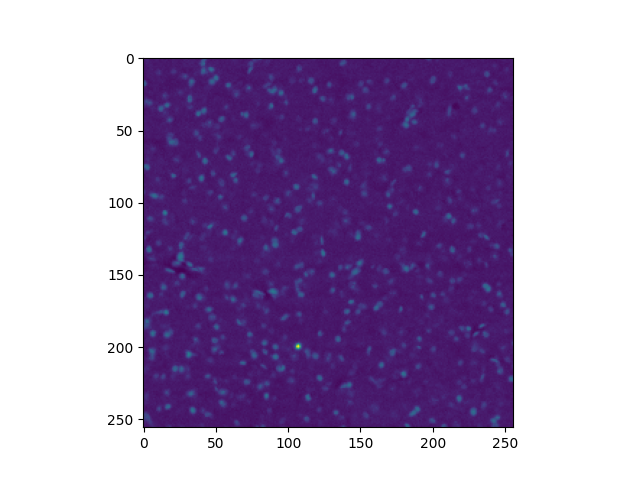

In [8]:
I = img[100]
fig, ax = plt.subplots()
ax.imshow(I)

## Apply the model + convert output to something useable

In [10]:
# Expects img to be shape [1, n_ch, row, col]

out = net(torch.tensor(I[None][None],dtype=dtype))
out.shape

torch.Size([1, 17, 32, 32])

/tmp/ipykernel_870776/417202015.py:131: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  points = L@circle + parameters[:,:2,None]


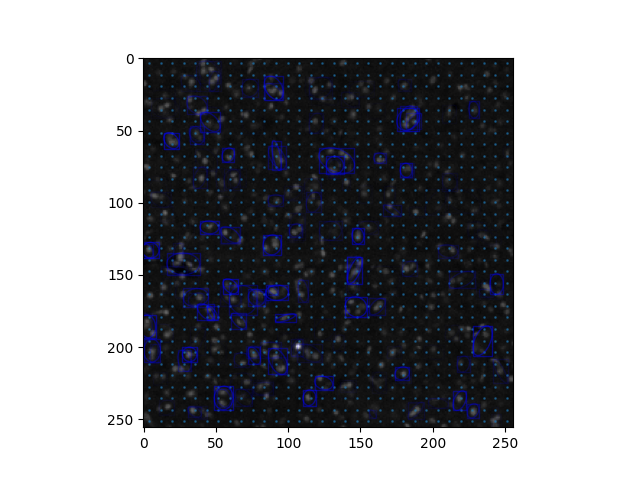

In [23]:
# for drawing, we start with a circle
ntheta = 20
thetas = np.arange(ntheta)/ntheta*2.0*np.pi 
circle = np.stack((np.cos(thetas),np.sin(thetas)))


B = net.B
C = net.C
stride = net.stride
parameters_,data = convert_data(out,B,C,stride)


fig,ax = plt.subplots()
x = torch.arange(out.shape[-1])*stride + (stride-1)/2
y = torch.arange(out.shape[-2])*stride + (stride-1)/2
YX = torch.stack(torch.meshgrid(y,x,indexing='ij'),0)
ax.imshow(I,cmap='gray')
ax.scatter(YX[1].ravel(),YX[0].ravel(),s=1,alpha=0.5)

bboxes_ = parameters_to_bboxes(parameters_)


c = data[...,-1]
predicted_rectangles = bboxes_to_rectangles(bboxes_,fc='none',ec='b',alpha=c.clone().detach()*0.5)
ax.add_collection(predicted_rectangles,)
scale = 1
predicted_polys = parameters_to_polys(parameters_*torch.tensor([1.0,1.0,1/scale,1/scale,1/scale,1/scale]),fc='none',ec='b',alpha=c.clone().detach()*0.5)
ax.add_collection(predicted_polys,)


# bboxes = parameters_to_bboxes(parameters)
# true_rectangles = bboxes_to_rectangles(bboxes,fc='none',ec='r')
# ax.add_collection(true_rectangles,)
# polys = parameters_to_polys(parameters,fc='none',ec='r')
# ax.add_collection(polys)
fig.canvas.draw()